In [2]:

import pandas as pd

# Official historical COVID-19 dataset
url = "https://covid.ourworldindata.org/data/owid-covid-data.csv"

# Load dataset directly into Google Colab
df = pd.read_csv(url)

# Display first five rows
display(df.head())

# Check dataset size
print("Dataset shape:", df.shape)

# Display column names
print("\nAvailable columns:")
print(df.columns.tolist())


URLError: <urlopen error [Errno -2] Name or service not known>

In [3]:

import requests
import pandas as pd
from io import BytesIO

url = "https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv"

response = requests.get(url, timeout=120)
response.raise_for_status()

df = pd.read_csv(BytesIO(response.content))

print("Dataset loaded successfully!")
print("Dataset size:", df.shape)

display(df.head())



Dataset loaded successfully!
Dataset size: (429435, 67)


,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,...,male_smokers,handwashing_facilities,hospital_beds_per_thousand,life_expectancy,human_development_index,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN


In [4]:

# Save the original dataset without changing it

df.to_csv(
    '/content/covid19_global_data_original.csv',
    index=False
)

print("Original dataset saved successfully!")


Original dataset saved successfully!


In [5]:

# 1. Dataset information
print("DATASET INFORMATION")
df.info()

# 2. Missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# 3. Duplicate records
print("\nDUPLICATE RECORDS")
print("Total duplicates:", df.duplicated().sum())

# 4. Date range
print("\nDATE RANGE")
print("First date:", df['date'].min())
print("Last date:", df['date'].max())

# 5. Number of unique locations
print("\nTOTAL LOCATIONS")
print(df['location'].nunique())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 429435 entries, 0 to 429434
Data columns (total 67 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   iso_code                                    429435 non-null  object 
 1   continent                                   402910 non-null  object 
 2   location                                    429435 non-null  object 
 3   date                                        429435 non-null  object 
 4   total_cases                                 411804 non-null  float64
 5   new_cases                                   410159 non-null  float64
 6   new_cases_smoothed                          408929 non-null  float64
 7   total_deaths                                411804 non-null  float64
 8   new_deaths                                  410608 non-null  float64
 9   new_deaths_smoothed                         409378

In [6]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Show only columns that have missing values
missing_values = missing_values[missing_values > 0]

print("Columns with missing values:")
print(missing_values)

Columns with missing values:
continent                                   26525
total_cases                                 17631
new_cases                                   19276
new_cases_smoothed                          20506
total_deaths                                17631
                                            ...  
human_development_index                    110308
excess_mortality_cumulative_absolute       416024
excess_mortality_cumulative                416024
excess_mortality                           416024
excess_mortality_cumulative_per_million    416024
Length: 63, dtype: int64


In [7]:
# Calculate missing values
missing_count = df.isnull().sum()

# Calculate missing percentage
missing_percentage = (missing_count / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    'Missing Values': missing_count,
    'Missing Percentage': missing_percentage.round(2)
})

# Show columns with missing values
missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
]

# Sort from highest to lowest
missing_summary = missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

display(missing_summary)

,Missing Values,Missing Percentage
weekly_icu_admissions,418442,97.44
weekly_icu_admissions_per_million,418442,97.44
excess_mortality_cumulative_per_million,416024,96.88
excess_mortality_cumulative_absolute,416024,96.88
excess_mortality_cumulative,416024,96.88
...,...,...
new_deaths_per_million,18827,4.38
total_deaths,17631,4.11
total_cases,17631,4.11
total_deaths_per_million,17631,4.11


In [8]:
# Display the 15 columns with the highest missing percentage
display(missing_summary.head(15))


,Missing Values,Missing Percentage
weekly_icu_admissions,418442,97.44
weekly_icu_admissions_per_million,418442,97.44
excess_mortality_cumulative_per_million,416024,96.88
excess_mortality_cumulative_absolute,416024,96.88
excess_mortality_cumulative,416024,96.88
excess_mortality,416024,96.88
weekly_hosp_admissions,404938,94.30
weekly_hosp_admissions_per_million,404938,94.30
icu_patients,390319,90.89
icu_patients_per_million,390319,90.89


In [9]:
# Select important columns for analysis

selected_columns = [
    'iso_code',
    'continent',
    'location',
    'date',
    'total_cases',
    'new_cases',
    'total_deaths',
    'new_deaths',
    'total_cases_per_million',
    'total_deaths_per_million',
    'population',
    'population_density',
    'median_age',
    'gdp_per_capita',
    'people_vaccinated',
    'people_fully_vaccinated'
]

# Create a separate working dataset
covid_df = df[selected_columns].copy()

print("Selected dataset created successfully!")
print("Dataset size:", covid_df.shape)

display(covid_df.head())

Selected dataset created successfully!
Dataset size: (429435, 16)


,iso_code,continent,location,date,total_cases,new_cases,total_deaths,new_deaths,total_cases_per_million,total_deaths_per_million,population,population_density,median_age,gdp_per_capita,people_vaccinated,people_fully_vaccinated
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0,0.0,0.0,0.0,0.0,41128772,54.42,18.6,1803.99,NaN,NaN
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0,0.0,0.0,0.0,0.0,41128772,54.42,18.6,1803.99,NaN,NaN
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0,0.0,0.0,0.0,0.0,41128772,54.42,18.6,1803.99,NaN,NaN
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0,0.0,0.0,0.0,0.0,41128772,54.42,18.6,1803.99,NaN,NaN
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0,0.0,0.0,0.0,0.0,41128772,54.42,18.6,1803.99,NaN,NaN


In [10]:
# Convert date column into datetime format
covid_df['date'] = pd.to_datetime(covid_df['date'])

# Check the data types
print("Column data types:")
print(covid_df.dtypes)

# Display first five records
display(covid_df.head())

Column data types:
iso_code                            object
continent                           object
location                            object
date                        datetime64[ns]
total_cases                        float64
new_cases                          float64
total_deaths                       float64
new_deaths                         float64
total_cases_per_million            float64
total_deaths_per_million           float64
population                           int64
population_density                 float64
median_age                         float64
gdp_per_capita                     float64
people_vaccinated                  float64
people_fully_vaccinated            float64
dtype: object


,iso_code,continent,location,date,total_cases,new_cases,total_deaths,new_deaths,total_cases_per_million,total_deaths_per_million,population,population_density,median_age,gdp_per_capita,people_vaccinated,people_fully_vaccinated
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0,0.0,0.0,0.0,0.0,41128772,54.42,18.6,1803.99,NaN,NaN
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0,0.0,0.0,0.0,0.0,41128772,54.42,18.6,1803.99,NaN,NaN
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0,0.0,0.0,0.0,0.0,41128772,54.42,18.6,1803.99,NaN,NaN
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0,0.0,0.0,0.0,0.0,41128772,54.42,18.6,1803.99,NaN,NaN
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0,0.0,0.0,0.0,0.0,41128772,54.42,18.6,1803.99,NaN,NaN


In [11]:
# Check missing values in selected dataset
print("Missing values in selected dataset:")
print(covid_df.isnull().sum())

Missing values in selected dataset:
iso_code                         0
continent                    26525
location                         0
date                             0
total_cases                  17631
new_cases                    19276
total_deaths                 17631
new_deaths                   18827
total_cases_per_million      17631
total_deaths_per_million     17631
population                       0
population_density           68943
median_age                   94772
gdp_per_capita              101143
people_vaccinated           348303
people_fully_vaccinated     351374
dtype: int64


In [12]:
# Save selected dataset
covid_df.to_csv(
    '/content/covid19_selected_data.csv',
    index=False
)

print("Selected dataset saved successfully!")

Selected dataset saved successfully!


In [13]:
# Check repeated location and date combinations
print(
    "Repeated location-date records:",
    covid_df.duplicated(subset=['location', 'date']).sum()
)

Repeated location-date records: 7770


In [14]:
# Find repeated location-date combinations
duplicate_records = covid_df[
    covid_df.duplicated(
        subset=['location', 'date'],
        keep=False
    )
]

# Sort records for easy inspection
duplicate_records = duplicate_records.sort_values(
    by=['location', 'date']
)

# Display first 20 repeated records
display(duplicate_records.head(20))

,iso_code,continent,location,date,total_cases,new_cases,total_deaths,new_deaths,total_cases_per_million,total_deaths_per_million,population,population_density,median_age,gdp_per_capita,people_vaccinated,people_fully_vaccinated
102540,TLS,Asia,East Timor,2021-02-12,80.0,0.0,0.0,0.0,58.42,0.0,1341298,87.18,18.0,6570.1,NaN,NaN
380675,TLS,Asia,East Timor,2021-02-12,NaN,NaN,NaN,NaN,NaN,NaN,1341298,87.18,18.0,6570.1,NaN,NaN
102541,TLS,Asia,East Timor,2021-02-13,80.0,0.0,0.0,0.0,58.42,0.0,1341298,87.18,18.0,6570.1,NaN,NaN
380676,TLS,Asia,East Timor,2021-02-13,NaN,NaN,NaN,NaN,NaN,NaN,1341298,87.18,18.0,6570.1,NaN,NaN
102542,TLS,Asia,East Timor,2021-02-14,102.0,22.0,0.0,0.0,74.49,0.0,1341298,87.18,18.0,6570.1,NaN,NaN
380677,TLS,Asia,East Timor,2021-02-14,NaN,NaN,NaN,NaN,NaN,NaN,1341298,87.18,18.0,6570.1,NaN,NaN
102543,TLS,Asia,East Timor,2021-02-15,102.0,0.0,0.0,0.0,74.49,0.0,1341298,87.18,18.0,6570.1,NaN,NaN
380678,TLS,Asia,East Timor,2021-02-15,NaN,NaN,NaN,NaN,NaN,NaN,1341298,87.18,18.0,6570.1,NaN,NaN
102544,TLS,Asia,East Timor,2021-02-16,102.0,0.0,0.0,0.0,74.49,0.0,1341298,87.18,18.0,6570.1,NaN,NaN
380679,TLS,Asia,East Timor,2021-02-16,NaN,NaN,NaN,NaN,NaN,NaN,1341298,87.18,18.0,6570.1,NaN,NaN


In [15]:
# Find repeated location-date combinations
duplicate_records = covid_df[
    covid_df.duplicated(
        subset=['location', 'date'],
        keep=False
    )
]

# Sort the records
duplicate_records = duplicate_records.sort_values(
    by=['location', 'date']
)

# Display first 20 records
display(duplicate_records.head(20))

,iso_code,continent,location,date,total_cases,new_cases,total_deaths,new_deaths,total_cases_per_million,total_deaths_per_million,population,population_density,median_age,gdp_per_capita,people_vaccinated,people_fully_vaccinated
102540,TLS,Asia,East Timor,2021-02-12,80.0,0.0,0.0,0.0,58.42,0.0,1341298,87.18,18.0,6570.1,NaN,NaN
380675,TLS,Asia,East Timor,2021-02-12,NaN,NaN,NaN,NaN,NaN,NaN,1341298,87.18,18.0,6570.1,NaN,NaN
102541,TLS,Asia,East Timor,2021-02-13,80.0,0.0,0.0,0.0,58.42,0.0,1341298,87.18,18.0,6570.1,NaN,NaN
380676,TLS,Asia,East Timor,2021-02-13,NaN,NaN,NaN,NaN,NaN,NaN,1341298,87.18,18.0,6570.1,NaN,NaN
102542,TLS,Asia,East Timor,2021-02-14,102.0,22.0,0.0,0.0,74.49,0.0,1341298,87.18,18.0,6570.1,NaN,NaN
380677,TLS,Asia,East Timor,2021-02-14,NaN,NaN,NaN,NaN,NaN,NaN,1341298,87.18,18.0,6570.1,NaN,NaN
102543,TLS,Asia,East Timor,2021-02-15,102.0,0.0,0.0,0.0,74.49,0.0,1341298,87.18,18.0,6570.1,NaN,NaN
380678,TLS,Asia,East Timor,2021-02-15,NaN,NaN,NaN,NaN,NaN,NaN,1341298,87.18,18.0,6570.1,NaN,NaN
102544,TLS,Asia,East Timor,2021-02-16,102.0,0.0,0.0,0.0,74.49,0.0,1341298,87.18,18.0,6570.1,NaN,NaN
380679,TLS,Asia,East Timor,2021-02-16,NaN,NaN,NaN,NaN,NaN,NaN,1341298,87.18,18.0,6570.1,NaN,NaN


In [16]:
# Count missing COVID-19 values in repeated records
print("Repeated records:", len(duplicate_records))

print(
    "Records with missing total_cases:",
    duplicate_records['total_cases'].isnull().sum()
)

print(
    "Records with missing total_deaths:",
    duplicate_records['total_deaths'].isnull().sum()
)

print(
    "Records with missing new_cases:",
    duplicate_records['new_cases'].isnull().sum()
)

Repeated records: 15540
Records with missing total_cases: 7770
Records with missing total_deaths: 7770
Records with missing new_cases: 7770


In [17]:
# Count records for each location and date
group_counts = covid_df.groupby(
    ['location', 'date']
).size()

print("Repeated group sizes:")
print(group_counts[group_counts > 1].value_counts())

# Check reported total cases in repeated groups
duplicate_check = duplicate_records.groupby(
    ['location', 'date']
).agg(
    total_records=('total_cases', 'size'),
    available_case_values=('total_cases', 'count')
)

print("\nRepeated group verification:")
print(duplicate_check.head(10))

Repeated group sizes:
2    7770
Name: count, dtype: int64

Repeated group verification:
                       total_records  available_case_values
location   date                                            
East Timor 2021-02-12              2                      1
           2021-02-13              2                      1
           2021-02-14              2                      1
           2021-02-15              2                      1
           2021-02-16              2                      1
           2021-02-17              2                      1
           2021-02-18              2                      1
           2021-02-19              2                      1
           2021-02-20              2                      1
           2021-02-21              2                      1


In [18]:
# Keep the records that contain reported total_cases
cleaned_df = covid_df.dropna(
    subset=['total_cases']
).copy()

print("Before cleaning:", covid_df.shape)
print("After cleaning:", cleaned_df.shape)

print(
    "Remaining repeated location-date records:",
    cleaned_df.duplicated(
        subset=['location', 'date']
    ).sum()
)

Before cleaning: (429435, 16)
After cleaning: (411804, 16)
Remaining repeated location-date records: 0


In [19]:
# Check missing values after cleaning
print("Missing values after cleaning:")
print(cleaned_df.isnull().sum())

# Check dataset size
print("\nCleaned dataset size:", cleaned_df.shape)

Missing values after cleaning:
iso_code                         0
continent                    20088
location                         0
date                             0
total_cases                      0
new_cases                     1645
total_deaths                     0
new_deaths                    1196
total_cases_per_million          0
total_deaths_per_million         0
population                       0
population_density           55242
median_age                   82026
gdp_per_capita               87048
people_vaccinated           342219
people_fully_vaccinated     345298
dtype: int64

Cleaned dataset size: (411804, 16)


In [20]:
# Calculate missing-value percentages
missing_percent = (
    cleaned_df.isnull().sum() / len(cleaned_df)
) * 100

# Create summary table
cleaning_summary = pd.DataFrame({
    'Missing Values': cleaned_df.isnull().sum(),
    'Missing Percentage': missing_percent.round(2)
})

display(cleaning_summary)

,Missing Values,Missing Percentage
iso_code,0,0.00
continent,20088,4.88
location,0,0.00
date,0,0.00
total_cases,0,0.00
new_cases,1645,0.40
total_deaths,0,0.00
new_deaths,1196,0.29
total_cases_per_million,0,0.00
total_deaths_per_million,0,0.00


In [21]:
# Count records for each location and date
group_size = covid_df.groupby(
    ['location', 'date']
)['location'].transform('size')

# Identify incomplete records within repeated groups
remove_mask = (
    (group_size > 1) &
    (covid_df['total_cases'].isnull())
)

# Create corrected cleaned dataset
cleaned_df = covid_df.loc[~remove_mask].copy()

print("Original dataset:", covid_df.shape)
print("Corrected dataset:", cleaned_df.shape)

print(
    "Remaining repeated location-date records:",
    cleaned_df.duplicated(
        subset=['location', 'date']
    ).sum()
)

print(
    "Remaining missing total_cases:",
    cleaned_df['total_cases'].isnull().sum()
)

Original dataset: (429435, 16)
Corrected dataset: (421665, 16)
Remaining repeated location-date records: 0
Remaining missing total_cases: 9861


In [22]:
# Check missing values in corrected dataset
print("Missing values in corrected dataset:")
print(cleaned_df.isnull().sum())

print("\nCorrected dataset size:", cleaned_df.shape)

Missing values in corrected dataset:
iso_code                         0
continent                    20163
location                         0
date                             0
total_cases                   9861
new_cases                    11506
total_deaths                  9861
new_deaths                   11057
total_cases_per_million       9861
total_deaths_per_million      9861
population                       0
population_density           62581
median_age                   88016
gdp_per_capita               94387
people_vaccinated           347144
people_fully_vaccinated     350104
dtype: int64

Corrected dataset size: (421665, 16)


In [23]:
# Save the corrected cleaned dataset
cleaned_df.to_csv(
    '/content/covid19_global_data_cleaned.csv',
    index=False
)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", cleaned_df.shape)

Cleaned dataset saved successfully!
Final dataset shape: (421665, 16)


In [24]:
from google.colab import files

files.download('covid19_global_data_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
import os

print(os.path.exists('/content/covid19_global_data_original.csv'))

True


In [26]:
import pandas as pd

cleaned_df = pd.read_csv(
    '/content/covid19_global_data_cleaned.csv'
)

cleaned_df['date'] = pd.to_datetime(cleaned_df['date'])

print("Cleaned dataset loaded successfully!")
print("Dataset shape:", cleaned_df.shape)

display(cleaned_df.head())

Cleaned dataset loaded successfully!
Dataset shape: (421665, 16)


,iso_code,continent,location,date,total_cases,new_cases,total_deaths,new_deaths,total_cases_per_million,total_deaths_per_million,population,population_density,median_age,gdp_per_capita,people_vaccinated,people_fully_vaccinated
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0,0.0,0.0,0.0,0.0,41128772,54.42,18.6,1803.99,NaN,NaN
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0,0.0,0.0,0.0,0.0,41128772,54.42,18.6,1803.99,NaN,NaN
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0,0.0,0.0,0.0,0.0,41128772,54.42,18.6,1803.99,NaN,NaN
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0,0.0,0.0,0.0,0.0,41128772,54.42,18.6,1803.99,NaN,NaN
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0,0.0,0.0,0.0,0.0,41128772,54.42,18.6,1803.99,NaN,NaN


In [27]:
countries = ['India', 'United States', 'United Kingdom']

country_data = cleaned_df[
    cleaned_df['location'].isin(countries)
].copy()

print("Country data extracted successfully!")
print("Total records:", country_data.shape[0])

print("\nRecords for each country:")
print(country_data['location'].value_counts())

display(country_data.head())

Country data extracted successfully!
Total records: 5030

Records for each country:
location
India             1682
United Kingdom    1674
United States     1674
Name: count, dtype: int64


,iso_code,continent,location,date,total_cases,new_cases,total_deaths,new_deaths,total_cases_per_million,total_deaths_per_million,population,population_density,median_age,gdp_per_capita,people_vaccinated,people_fully_vaccinated
170473,IND,Asia,India,2020-01-05,0.0,0.0,0.0,0.0,0.0,0.0,1417173120,450.42,28.2,6426.67,NaN,NaN
170474,IND,Asia,India,2020-01-06,0.0,0.0,0.0,0.0,0.0,0.0,1417173120,450.42,28.2,6426.67,NaN,NaN
170475,IND,Asia,India,2020-01-07,0.0,0.0,0.0,0.0,0.0,0.0,1417173120,450.42,28.2,6426.67,NaN,NaN
170476,IND,Asia,India,2020-01-08,0.0,0.0,0.0,0.0,0.0,0.0,1417173120,450.42,28.2,6426.67,NaN,NaN
170477,IND,Asia,India,2020-01-09,0.0,0.0,0.0,0.0,0.0,0.0,1417173120,450.42,28.2,6426.67,NaN,NaN


In [28]:
summary = country_data.groupby('location').agg(
    Total_Cases=('total_cases', 'max'),
    Total_Deaths=('total_deaths', 'max'),
    People_Vaccinated=('people_vaccinated', 'max'),
    Fully_Vaccinated=('people_fully_vaccinated', 'max'),
    Population=('population', 'first')
).reset_index()

print("COVID-19 Country-wise Summary:")
display(summary)

COVID-19 Country-wise Summary:


,location,Total_Cases,Total_Deaths,People_Vaccinated,Fully_Vaccinated,Population
0,India,45041748.0,533623.0,1.027439e+09,951990552.0,1417173120
1,United Kingdom,24974629.0,232112.0,5.381349e+07,50762968.0,67508936
2,United States,103436829.0,1193165.0,2.702272e+08,230637348.0,338289856


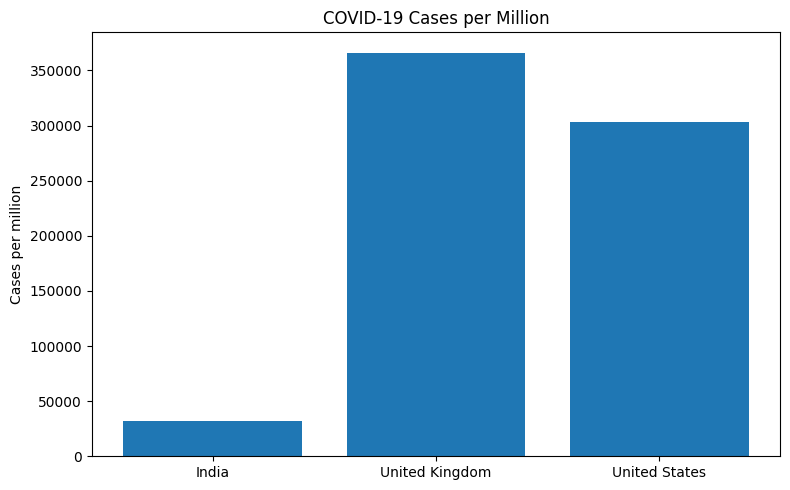

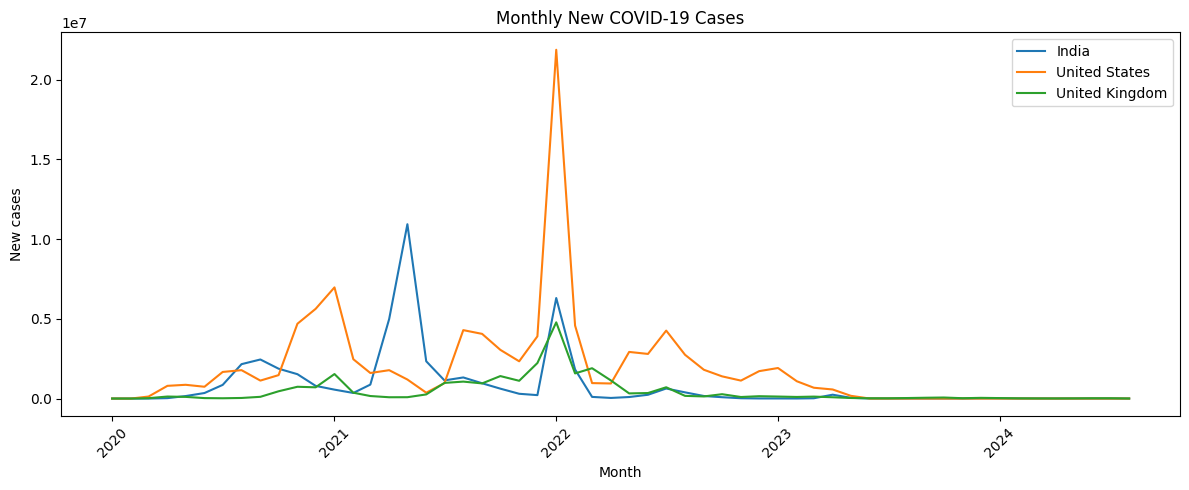

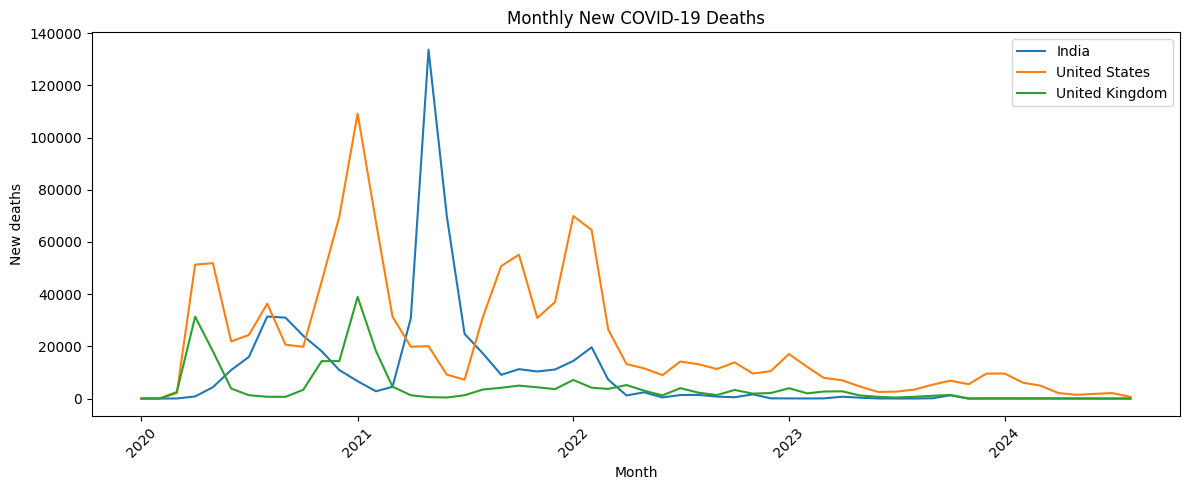

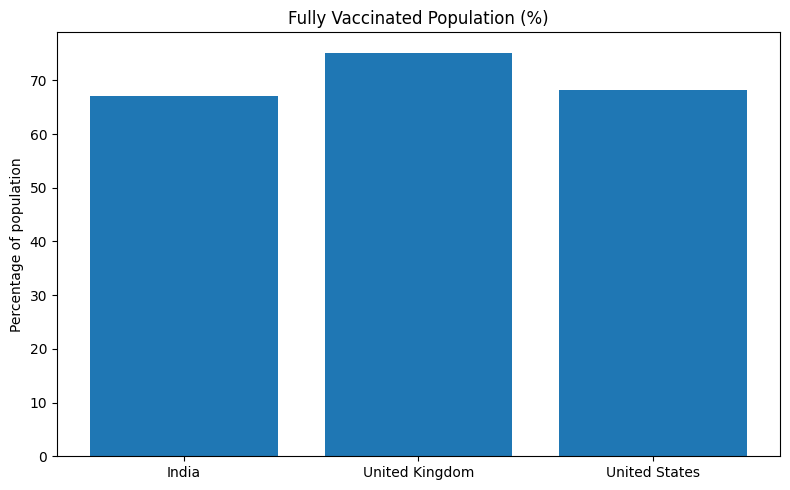

All 4 charts generated successfully!


In [29]:
import matplotlib.pyplot as plt
import pandas as pd

# Prepare monthly data
country_data['month'] = (
    country_data['date'].dt.to_period('M').dt.to_timestamp()
)

monthly = country_data.groupby(
    ['month', 'location']
).agg(
    New_Cases=('new_cases', 'sum'),
    New_Deaths=('new_deaths', 'sum')
).reset_index()

# Get latest available cumulative values
latest = country_data.sort_values('date').groupby('location').agg(
    Cases_Per_Million=('total_cases_per_million', 'last'),
    Deaths_Per_Million=('total_deaths_per_million', 'last'),
    Fully_Vaccinated=('people_fully_vaccinated', 'max'),
    Population=('population', 'first')
).reset_index()

latest['Vaccination_Percentage'] = (
    latest['Fully_Vaccinated'] / latest['Population']
) * 100

# CHART 1: Total cases per million
plt.figure(figsize=(8, 5))
plt.bar(latest['location'], latest['Cases_Per_Million'])
plt.title('COVID-19 Cases per Million')
plt.ylabel('Cases per million')
plt.tight_layout()
plt.show()

# CHART 2: Monthly new cases
plt.figure(figsize=(12, 5))
for country in countries:
    data = monthly[monthly['location'] == country]
    plt.plot(data['month'], data['New_Cases'], label=country)

plt.title('Monthly New COVID-19 Cases')
plt.xlabel('Month')
plt.ylabel('New cases')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# CHART 3: Monthly new deaths
plt.figure(figsize=(12, 5))
for country in countries:
    data = monthly[monthly['location'] == country]
    plt.plot(data['month'], data['New_Deaths'], label=country)

plt.title('Monthly New COVID-19 Deaths')
plt.xlabel('Month')
plt.ylabel('New deaths')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# CHART 4: Vaccination percentage
plt.figure(figsize=(8, 5))
plt.bar(latest['location'], latest['Vaccination_Percentage'])
plt.title('Fully Vaccinated Population (%)')
plt.ylabel('Percentage of population')
plt.tight_layout()
plt.show()

print("All 4 charts generated successfully!")

In [30]:
# Find the month with the highest new cases and deaths
for country in countries:
    data = monthly[monthly['location'] == country]

    peak_cases = data.loc[data['New_Cases'].idxmax()]
    peak_deaths = data.loc[data['New_Deaths'].idxmax()]

    print(f"\n{country}")
    print("Peak new cases:", int(peak_cases['New_Cases']))
    print("Peak cases month:", peak_cases['month'].strftime('%B %Y'))
    print("Peak new deaths:", int(peak_deaths['New_Deaths']))
    print("Peak deaths month:", peak_deaths['month'].strftime('%B %Y'))

print("\nCountry-wise total cases and deaths:")
display(summary)


India
Peak new cases: 10934628
Peak cases month: May 2021
Peak new deaths: 133661
Peak deaths month: May 2021

United States
Peak new cases: 21878018
Peak cases month: January 2022
Peak new deaths: 109203
Peak deaths month: January 2021

United Kingdom
Peak new cases: 4779759
Peak cases month: January 2022
Peak new deaths: 38945
Peak deaths month: January 2021

Country-wise total cases and deaths:


,location,Total_Cases,Total_Deaths,People_Vaccinated,Fully_Vaccinated,Population
0,India,45041748.0,533623.0,1.027439e+09,951990552.0,1417173120
1,United Kingdom,24974629.0,232112.0,5.381349e+07,50762968.0,67508936
2,United States,103436829.0,1193165.0,2.702272e+08,230637348.0,338289856


In [31]:
!pip -q install reportlab

from reportlab.lib.pagesizes import A4
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
)
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.units import cm

file_path = '/content/COVID19_Executive_Summary.pdf'

doc = SimpleDocTemplate(
    file_path,
    pagesize=A4,
    rightMargin=1.7*cm,
    leftMargin=1.7*cm,
    topMargin=1.5*cm,
    bottomMargin=1.5*cm
)

styles = getSampleStyleSheet()
story = []

story.append(Paragraph(
    "COVID-19 GLOBAL IMPACT ANALYSIS",
    styles['Title']
))
story.append(Spacer(1, 8))

story.append(Paragraph(
    "<b>Project Overview</b>",
    styles['Heading2']
))
story.append(Paragraph(
    "This project analyses the impact of COVID-19 in India, "
    "the United States, and the United Kingdom using historical "
    "data from Our World in Data (OWID). The analysis focuses "
    "on reported cases, deaths, and vaccination figures.",
    styles['BodyText']
))
story.append(Spacer(1, 10))

story.append(Paragraph(
    "<b>Country-wise Statistics</b>",
    styles['Heading2']
))

table_data = [
    ['Country', 'Total Cases', 'Total Deaths'],
    ['India', '45.04 million', '533,623'],
    ['United Kingdom', '24.97 million', '232,112'],
    ['United States', '103.44 million', '1,193,165']
]

table = Table(table_data, colWidths=[5*cm, 5*cm, 5*cm])
table.setStyle(TableStyle([
    ('BACKGROUND', (0,0), (-1,0), colors.HexColor('#24476B')),
    ('TEXTCOLOR', (0,0), (-1,0), colors.white),
    ('GRID', (0,0), (-1,-1), 0.5, colors.grey),
    ('PADDING', (0,0), (-1,-1), 7),
    ('FONTNAME', (0,0), (-1,0), 'Helvetica-Bold'),
]))
story.append(table)
story.append(Spacer(1, 10))

story.append(Paragraph(
    "<b>Key Findings</b>",
    styles['Heading2']
))

insights = [
    "1. The United States recorded the highest total cases "
    "and deaths among the three countries.",
    "2. India experienced its highest monthly new cases "
    "and deaths in May 2021.",
    "3. The USA and UK recorded their highest monthly new "
    "cases in January 2022.",
    "4. Monthly reported deaths generally declined after 2022 "
    "across all three countries.",
    "5. Vaccination data shows substantial reported vaccination "
    "coverage in all three countries."
]

for item in insights:
    story.append(Paragraph(item, styles['BodyText']))
    story.append(Spacer(1, 5))

story.append(Spacer(1, 5))
story.append(Paragraph(
    "<b>Conclusion</b>",
    styles['Heading2']
))
story.append(Paragraph(
    "The analysis highlights differences in the COVID-19 impact "
    "across the three countries. The USA had the highest reported "
    "cumulative cases and deaths, while India experienced a major "
    "wave in May 2021. The charts help identify trends over time "
    "and compare the countries.",
    styles['BodyText']
))

story.append(Spacer(1, 8))
story.append(Paragraph(
    "<b>Data Source:</b> Our World in Data – COVID-19 Dataset "
    "(historical data through 14 August 2024).",
    styles['BodyText']
))

doc.build(story)

print("Executive Summary PDF created successfully!")

from google.colab import files
files.download(file_path)

Executive Summary PDF created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>